<a href="https://colab.research.google.com/github/fesilveiraeng/Trabalho_IA/blob/main/BuscasClassicas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
#Conecta ao Google Drive

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from collections import deque
from heapq import heappush, heappop
from itertools import count
from time import perf_counter
import random
import statistics
import matplotlib.pyplot as plt
import time
import os
import psutil
import pandas as pd


Greedy-blocos | concluído=True | custo=5 | expandidos=5 | tempo=0.000017s
Inicial: 00001001000011001100111
  1: flip[4:4] -> 00000001000011001100111
  2: flip[7:7] -> 00000000000011001100111
  3: flip[12:13] -> 00000000000000001100111
  4: flip[16:17] -> 00000000000000000000111
  5: flip[20:22] -> 00000000000000000000000
Alvo:    00000000000000000000000

Greedy-fila | concluído=True | custo=5 | expandidos=5 | tempo=0.001105s
Inicial: 00001001000011001100111
  1: flip[4:4] -> 00000001000011001100111
  2: flip[7:7] -> 00000000000011001100111
  3: flip[12:13] -> 00000000000000001100111
  4: flip[16:17] -> 00000000000000000000111
  5: flip[20:22] -> 00000000000000000000000
Alvo:    00000000000000000000000

Experimentos com 30 pares por comprimento
{'L': 2, 'metodo': 'BFS', 'concluidos': 30, 'tentativas': 30, 'custo_medio': 0.5333333333333333, 'tempo_medio_s': 2.278700007233662e-06, 'expandidos_medios': 0.5333333333333333, 'interrompidos': 0}
{'L': 2, 'metodo': 'Greedy-blocos', 'concluidos

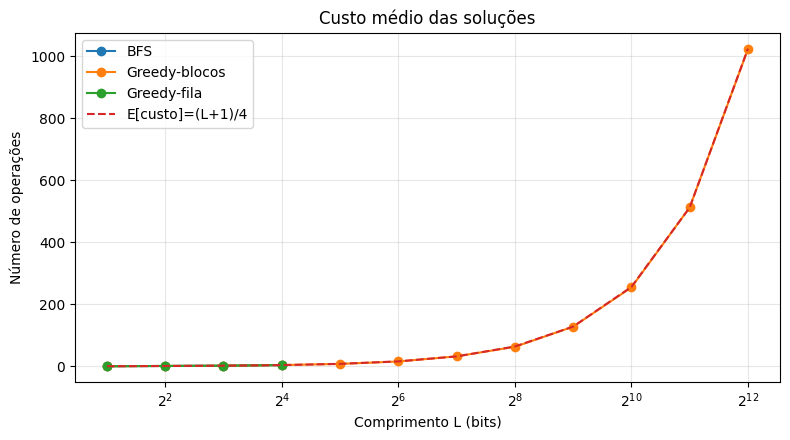

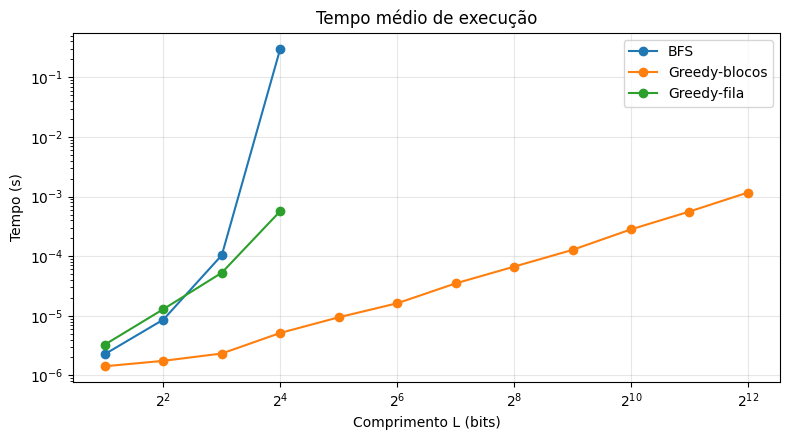

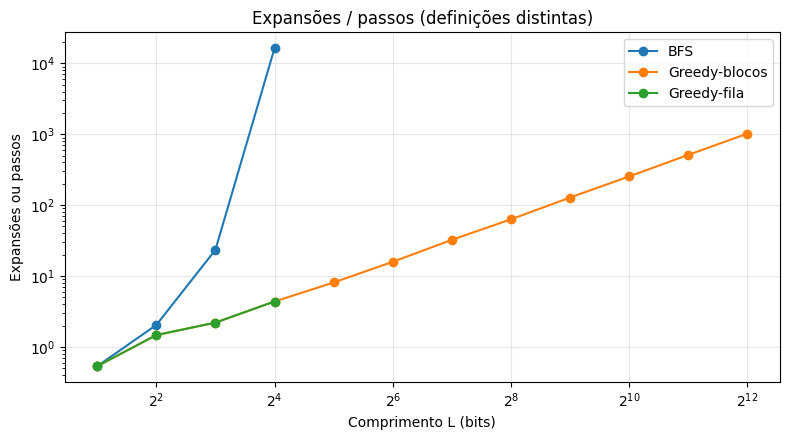


TABELA PARA O RELATÓRIO (ms)
metodo       BFS  Greedy-fila  Greedy-blocos
L                                           
2         0.0023       0.0033         0.0014
4         0.0086       0.0129         0.0018
8         0.1042       0.0528         0.0023
16      302.3201       0.5708         0.0052
32           NaN          NaN         0.0094
64           NaN          NaN         0.0162
128          NaN          NaN         0.0350
256          NaN          NaN         0.0668
512          NaN          NaN         0.1276
1024         NaN          NaN         0.2818
2048         NaN          NaN         0.5609
4096         NaN          NaN         1.1698


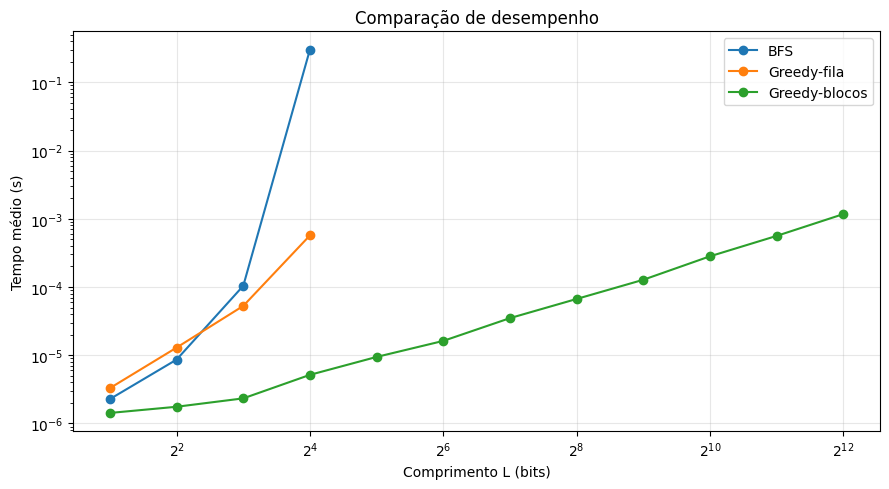

In [9]:
EXEMPLO = "00001001000011001100111"


def validar(inicial, alvo):
    if not inicial or len(inicial) != len(alvo) or set(inicial + alvo) - {"0", "1"}:
        raise ValueError("Sequências binárias não vazias e de mesmo comprimento são necessárias.")


def mascara_intervalo(L, i, j):
    if not (0 <= i <= j < L):
        raise ValueError("Intervalo inválido")
    # O índice zero da sequência é o bit mais significativo.
    return ((1 << (j - i + 1)) - 1) << (L - 1 - j)


def flip_intervalo(estado, i, j):
    """Retorna uma nova string após inverter o intervalo [i,j]."""
    if not estado or set(estado) - {"0", "1"}:
        raise ValueError("Estado inválido")
    L = len(estado)
    return format(int(estado, 2) ^ mascara_intervalo(L, i, j), f"0{L}b")


def flip_bit(estado, i):
    return flip_intervalo(estado, i, i)


def intervalos_diferentes(estado, alvo):
    """Blocos máximos de diferenças, em ordem crescente de posição."""
    validar(estado, alvo)
    resultado = []
    inicio = None
    for i, (a, b) in enumerate(zip(estado, alvo)):
        if a != b and inicio is None:
            inicio = i
        elif a == b and inicio is not None:
            resultado.append((inicio, i - 1))
            inicio = None
    if inicio is not None:
        resultado.append((inicio, len(estado) - 1))
    return resultado


def custo_otimo(estado, alvo):
    """Teorema: mínimo de flips = número de blocos de diferenças."""
    return len(intervalos_diferentes(estado, alvo))


def _resultado(ops, expandidos, descobertos, tempo, concluido, algoritmo):
    return {
        "algoritmo": algoritmo,
        "operacoes": ops if concluido else None,
        "custo": len(ops) if concluido else None,
        "expandidos": expandidos,
        "descobertos": descobertos,
        "tempo_s": tempo,
        "concluiu": concluido,
    }


def _reconstruir(pais, destino):
    ops = []
    while pais[destino] is not None:
        anterior, intervalo = pais[destino]
        ops.append(intervalo)
        destino = anterior
    return list(reversed(ops))


def bfs(inicial, alvo, limite_estados=300_000):
    """BFS explícita, estados inteiros e XOR; interrompe ao atingir limite de memória."""
    validar(inicial, alvo)
    L = len(inicial)
    origem, destino = int(inicial, 2), int(alvo, 2)
    inicio_t = perf_counter()
    if origem == destino:
        return _resultado([], 0, 1, perf_counter()-inicio_t, True, "BFS")
    mascaras = [(mascara_intervalo(L, i, j), (i, j))
                for i in range(L) for j in range(i, L)]
    fila = deque([origem])
    pais = {origem: None}
    expandidos = 0
    while fila:
        atual = fila.popleft()
        expandidos += 1
        for mascara, intervalo in mascaras:
            proximo = atual ^ mascara
            if proximo in pais:
                continue
            # Verificar objetivo antes de adicionar outros estados.
            pais[proximo] = (atual, intervalo)
            if proximo == destino:
                ops = _reconstruir(pais, destino)
                return _resultado(ops, expandidos, len(pais),
                                  perf_counter()-inicio_t, True, "BFS")
            if len(pais) >= limite_estados:
                return _resultado(None, expandidos, len(pais),
                                  perf_counter()-inicio_t, False, "BFS")
            fila.append(proximo)
    return _resultado(None, expandidos, len(pais), perf_counter()-inicio_t, False, "BFS")


def greedy_fila(inicial, alvo, limite_estados=300_000):
    """Greedy Best-First genuína: prioridade h=blocos diferentes.

    Explora todos os sucessores do estado escolhido. Recomendada apenas para L pequeno.
    """
    validar(inicial, alvo)
    L = len(inicial)
    origem, destino = int(inicial, 2), int(alvo, 2)
    inicio_t = perf_counter()
    if origem == destino:
        return _resultado([], 0, 1, perf_counter()-inicio_t, True, "Greedy-fila")
    mascaras = [(mascara_intervalo(L, i, j), (i, j))
                for i in range(L) for j in range(i, L)]
    def h(estado):
        diferenca = estado ^ destino
        # Conta inícios de blocos 1 no XOR (em qualquer orientação).
        return (diferenca & ~(diferenca >> 1)).bit_count()
    ordem = count()
    heap = [(h(origem), next(ordem), origem)]
    pais = {origem: None}
    visitados = set()
    expandidos = 0
    while heap:
        _, _, atual = heappop(heap)
        if atual in visitados:
            continue
        if atual == destino:
            ops = _reconstruir(pais, destino)
            return _resultado(ops, expandidos, len(pais),
                              perf_counter()-inicio_t, True, "Greedy-fila")
        visitados.add(atual)
        expandidos += 1
        for mascara, intervalo in mascaras:
            proximo = atual ^ mascara
            if proximo not in pais:
                pais[proximo] = (atual, intervalo)
                if len(pais) >= limite_estados:
                    return _resultado(None, expandidos, len(pais),
                                      perf_counter()-inicio_t, False, "Greedy-fila")
                heappush(heap, (h(proximo), next(ordem), proximo))
    return _resultado(None, expandidos, len(pais), perf_counter()-inicio_t, False, "Greedy-fila")


def greedy_blocos(inicial, alvo):
    """Versão gulosa especializada, sem enumerar vizinhos.

    Corrige um bloco máximo de diferenças por passo. É ótima neste problema
    porque o custo unitário de cada flip não depende do tamanho do intervalo.
    """
    validar(inicial, alvo)
    t0 = perf_counter()
    ops = intervalos_diferentes(inicial, alvo)
    return _resultado(ops, len(ops), len(ops)+1,
                      perf_counter()-t0, True, "Greedy-blocos")


def mostrar_solucao(inicial, alvo, resultado):
    print(f"\n{resultado['algoritmo']} | concluído={resultado['concluiu']} | "
          f"custo={resultado['custo']} | expandidos={resultado['expandidos']} | "
          f"tempo={resultado['tempo_s']:.6f}s")
    if not resultado["concluiu"]:
        print("Busca interrompida pelo limite de estados; não atribuir custo zero.")
        return
    atual = inicial
    print("Inicial:", atual)
    for passo, (i, j) in enumerate(resultado["operacoes"], 1):
        atual = flip_intervalo(atual, i, j)
        print(f"{passo:>3}: flip[{i}:{j}] -> {atual}")
    assert atual == alvo, "O caminho retornado não alcançou o alvo!"
    print("Alvo:   ", alvo)


def experimento(comprimentos=None, pares=30, semente=42, max_bfs=16,
                max_greedy_fila=16, limite_estados=300_000):
    """Mede os mesmos pares aleatórios por comprimento; None indica não executado."""
    if comprimentos is None:
        comprimentos = [2**k for k in range(1, 13)]
    rng = random.Random(semente)
    registros = []
    for L in comprimentos:
        for repeticao in range(pares):
            inicial = "".join(str(rng.getrandbits(1)) for _ in range(L))
            alvo = "".join(str(rng.getrandbits(1)) for _ in range(L))
            otimo = custo_otimo(inicial, alvo)
            metodos = [greedy_blocos(inicial, alvo)]
            if L <= max_greedy_fila:
                metodos.append(greedy_fila(inicial, alvo, limite_estados))
            if L <= max_bfs:
                metodos.append(bfs(inicial, alvo, limite_estados))
            for r in metodos:
                if r["concluiu"]:
                    assert r["custo"] == otimo, (
                        f"Custo inesperado: {r['algoritmo']}, L={L}, "
                        f"{r['custo']} != {otimo}"
                    )
                registros.append({
                    "L": L, "par": repeticao, "metodo": r["algoritmo"],
                    "custo": r["custo"], "custo_otimo": otimo,
                    "tempo_s": r["tempo_s"], "expandidos": r["expandidos"],
                    "descobertos": r["descobertos"], "concluiu": r["concluiu"],
                })
    return registros


def resumir(registros):
    grupos = {}
    for r in registros:
        grupos.setdefault((r["L"], r["metodo"]), []).append(r)
    resumo = []
    for (L, metodo), itens in sorted(grupos.items()):
        concluidos = [r for r in itens if r["concluiu"]]
        resumo.append({
            "L": L, "metodo": metodo,
            "concluidos": len(concluidos), "tentativas": len(itens),
            "custo_medio": statistics.mean(r["custo"] for r in concluidos)
                           if concluidos else None,
            "tempo_medio_s": statistics.mean(r["tempo_s"] for r in concluidos)
                             if concluidos else None,
            "expandidos_medios": statistics.mean(r["expandidos"] for r in concluidos)
                                 if concluidos else None,
            "interrompidos": len(itens) - len(concluidos),
        })
    return resumo


def plotar(registros):
    resumo = resumir(registros)
    metodos = sorted({r["metodo"] for r in resumo})
    # Figuras separadas: custo, tempo e expansões.
    for chave, titulo, ylabel, log_y in [
        ("custo_medio", "Custo médio das soluções", "Número de operações", False),
        ("tempo_medio_s", "Tempo médio de execução", "Tempo (s)", True),
        ("expandidos_medios", "Expansões / passos (definições distintas)", "Expansões ou passos", True),
    ]:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for metodo in metodos:
            pontos = [r for r in resumo if r["metodo"] == metodo
                      and r[chave] is not None]
            if pontos:
                ax.plot([r["L"] for r in pontos],
                        [r[chave] for r in pontos], marker="o", label=metodo)
        if chave == "custo_medio":
            xs = sorted({r["L"] for r in resumo})
            ax.plot(xs, [(L+1)/4 for L in xs], "--", label="E[custo]=(L+1)/4")
        ax.set_xscale("log", base=2)
        if log_y:
            ax.set_yscale("log")
        ax.set_xlabel("Comprimento L (bits)")
        ax.set_ylabel(ylabel)
        ax.set_title(titulo)
        ax.grid(True, alpha=0.3)
        ax.legend()
        fig.tight_layout()
        plt.show()


if __name__ == "__main__":
    alvo = "0" * len(EXEMPLO)
    # BFS do exemplo de 23 bits pode consumir milhões de estados:
    # executar separadamente somente com RAM/tempo suficientes.
    mostrar_solucao(EXEMPLO, alvo, greedy_blocos(EXEMPLO, alvo))
    mostrar_solucao(EXEMPLO, alvo, greedy_fila(EXEMPLO, alvo))
    # A BFS de 23 bits é OPCIONAL: pode exigir milhões de estados e muita RAM.
    EXECUTAR_BFS_23 = False
    if EXECUTAR_BFS_23:
        print("\nBFS oficial (23 bits): pode exigir muita memória/tempo")
        mostrar_solucao(EXEMPLO, alvo, bfs(EXEMPLO, alvo, limite_estados=3_000_000))

    print("\nExperimentos com 30 pares por comprimento")
    dados = experimento(pares=30, max_bfs=16, max_greedy_fila=16,
                        limite_estados=300_000)
    for linha in resumir(dados):
        print(linha)

    # CSVs prontos para análise e inclusão no relatório.
    import csv
    with open("resultados_buscas.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(dados[0]))
        writer.writeheader()
        writer.writerows(dados)
    resumo = resumir(dados)
    with open("resumo_buscas.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(resumo[0]))
        writer.writeheader()
        writer.writerows(resumo)
    print("\nArquivos salvos: resultados_buscas.csv e resumo_buscas.csv")
    print("Nota: 'expandidos' na Greedy-blocos representa passos de correção, ")
    print("não expansões de estados equivalentes às da BFS.")
    plotar(dados)

    # TABELA E GRÁFICO COM OS MESMOS RESULTADOS

    df = pd.DataFrame(resumo)

    # Tabela de tempos médios em milissegundos
    tabela = df.pivot(
        index="L",
        columns="metodo",
        values="tempo_medio_s"
    ) * 1000

    tabela = tabela.reindex(
        columns=["BFS", "Greedy-fila", "Greedy-blocos"]
    )

    print("\nTABELA PARA O RELATÓRIO (ms)")
    print(tabela.round(4).to_string())

    # Gráfico utilizando os mesmos valores da tabela
    fig, ax = plt.subplots(figsize=(9, 5))

    for metodo in tabela.columns:
        serie = tabela[metodo].dropna()

        if not serie.empty:
            ax.plot(
                serie.index,
                serie.values / 1000,
                marker="o",
                label=metodo
            )

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Comprimento L (bits)")
    ax.set_ylabel("Tempo médio (s)")
    ax.set_title("Comparação de desempenho")
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig("comparacao_buscas.pdf", bbox_inches="tight")
    plt.show()



In [10]:
# Sequência oficial do professor
inicial = "00001001000011001100111"
alvo = "0" * len(inicial)

# Processo do Colab
processo = psutil.Process(os.getpid())

def memoria_mb():
    return processo.memory_info().rss / (1024 ** 2)

print("Executando BFS para 23 bits...")
print("Memória inicial:", round(memoria_mb(), 2), "MB")

inicio_tempo = time.perf_counter()

resultado_bfs = bfs(
    inicial,
    alvo,
    limite_estados=3_000_000
)

tempo_total = time.perf_counter() - inicio_tempo

print("\nRESULTADOS BFS")
print("Concluiu:", resultado_bfs["concluiu"])
print("Custo:", resultado_bfs["custo"])
print("Estados expandidos:", resultado_bfs["expandidos"])
print("Estados descobertos:", resultado_bfs["descobertos"])
print("Tempo total:", round(tempo_total, 4), "s")
print("Memória final:", round(memoria_mb(), 2), "MB")

if resultado_bfs["concluiu"]:
    mostrar_solucao(inicial, alvo, resultado_bfs)
else:
    print("Busca interrompida pelo limite de estados.")

Executando BFS para 23 bits...
Memória inicial: 200.7 MB

RESULTADOS BFS
Concluiu: True
Custo: 5
Estados expandidos: 762113
Estados descobertos: 2681287
Tempo total: 49.7378 s
Memória final: 216.57 MB

BFS | concluído=True | custo=5 | expandidos=762113 | tempo=49.586231s
Inicial: 00001001000011001100111
  1: flip[4:4] -> 00000001000011001100111
  2: flip[7:7] -> 00000000000011001100111
  3: flip[12:13] -> 00000000000000001100111
  4: flip[16:17] -> 00000000000000000000111
  5: flip[20:22] -> 00000000000000000000000
Alvo:    00000000000000000000000
